# 9. Street network analysis

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/09_analysis.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/09_analysis.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-9.svg" alt="duckOSM notebook manual, chapter 9: Street network analysis" width="100%">

| **You learn** | the two views of the statistics; junctions; street bearings and their entropy; connected components; the nearest node and edge of a point; a smaller area; random points; heights and grades; OSMnx on a duckOSM network; city blocks with momepy |
|---|---|
| **Time** | about 2 minutes |
| **Extras** | `duckosm[analysis,viz]` (the install cell installs them) |
| **Next** | [10. OSM data for GIS](10_gis.md): OSM features, OSM XML and administrative areas |

In [ ]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, os, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[analysis,viz] @ {nightly_wheel()}"
    %pip install -q osmnx momepy mapclassify
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## What street network analysis measures

Street network analysis describes the form of a road network with numbers. How many junctions does a city have? How
long is a street on average? Do the streets make a grid? Can you drive from each place to each other place? Urban
planners and researchers ask these questions, and the Python library OSMnx answers them for OpenStreetMap data.

The module `duckosm.analysis` gives the functions of OSMnx 2 on a duckOSM network. The counts, the bearings, the
components and the nearest searches run in Rust, on the tables of the file. Each function takes a mode view
(`net.driving`), a network with one mode, or a path with `mode=`.

| Question | duckOSM | OSMnx |
|---|---|---|
| How large is the network? | `stats` | `basic_stats` |
| How many streets meet at each node? | `streets_per_node` | `count_streets_per_node` |
| In which direction does each street go? | `bearings`, `orientation_entropy`, `plot_orientation` | `add_edge_bearings`, `orientation_entropy`, `plot_orientation` |
| Which parts are connected? | `components`, `largest_component` | networkx, `largest_component` |
| Which node or edge is nearest to a point? | `nearest_nodes`, `nearest_edges` | `nearest_nodes`, `nearest_edges` |
| What is in a smaller area? | `clip` | `truncate_graph_bbox`, `truncate_graph_polygon` |
| How steep is each street? | `add_elevation`, `grades` | `add_node_elevations_raster`, `add_edge_grades` |
| Where are random points on the streets? | `sample_points` | `sample_points` |
| Can OSMnx itself work on it? | `to_osmnx` | the OSMnx graph |

The guide [duckOSM for OSMnx users](../compare/for-osmnx-users.md) gives the duckOSM call for each OSMnx call.

### Two views of one network

duckOSM and OSMnx cut the roads at different places. OSMnx keeps a node only where the streets meet or end
(`simplify_graph`). duckOSM also cuts a road where another mode joins it, where its tags change and where an OSM way
ends, because your data joins to each of these edges by `edge_id`. So a duckOSM network has more nodes and edges than
the OSMnx graph of the same area.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/stats-views.svg" alt="The duckosm view keeps every node, and the osmnx view removes the nodes where only two roads meet" width="100%">

`stats` gives each number in two views:

| View | Nodes and edges | Use it |
|---|---|---|
| `osmnx` | a node where a road only passes through (it has exactly 2 neighbor nodes) is removed, and its two edges become one edge | to compare with OSMnx and with published OSMnx numbers |
| `duckosm` | every row of `<mode>.nodes` and `<mode>.edges` | to count the rows that your data joins to |

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> The `osmnx` view gives the numbers that OSMnx gives for the same roads. The `duckosm` view counts the rows of the file. Use the `osmnx` view to compare cities, and the `duckosm` view to plan your own data.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This chapter opens that file with `duckosm.open`: it builds nothing. The analysis uses the driving network,
`net.driving`. `an` is the short name of the module.

In [2]:
from duckosm import analysis as an      # the module of this chapter
net = duckosm.open("monaco.duckdb")     # the network of chapter 1: Monaco, three modes
net.driving                             # the card of the driving mode

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


## Statistics: `stats`

`stats(view)` gives the numbers of OSMnx `basic_stats` as a DataFrame: one row for each key, one column for each view.
`net.driving.stats()` gives the same table.

| Key | What it is |
|---|---|
| `n`, `m` | the number of nodes and of edges (a two-way road is two edges) |
| `k_avg` | the average degree: 2 × `m` / `n` |
| `edge_length_total`, `edge_length_avg` | the sum and the average of the edge lengths, in metres |
| `streets_per_node_avg` | the average number of streets at a node |
| `intersection_count` | the nodes with 2 or more streets (OSMnx's rule) |
| `street_length_total`, `street_segment_count`, `street_length_avg` | the same as the edge keys, with a two-way road counted once |
| `circuity_avg` | the length of the streets divided by the straight distance between their ends |
| `self_loop_proportion` | the share of edges that start and end at the same node |

In [3]:
s = an.stats(net.driving)                                                       # both views, the keys of OSMnx basic_stats
s.drop(["streets_per_node_counts", "streets_per_node_proportions"])       # the numbers (the two dicts follow)

,osmnx,duckosm
n,843,1768
m,1484,2840
k_avg,3.520759,3.21267
edge_length_total,96058.971143,96207.398536
edge_length_avg,64.729765,33.875845
streets_per_node_avg,2.537367,2.256787
intersection_count,636,1561
street_length_total,65778.865675,65866.686087
street_segment_count,1070,1997
street_length_avg,61.475575,32.982817


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The `duckosm` view counts 1,768 nodes and 2,840 edges: the rows of the file. The `osmnx` view counts 843 nodes and 1,484 edges, about half. The lengths are almost the same (65.8 km and 65.9 km of streets), because the same roads are in both views. So the average street is 61 m in the `osmnx` view and 33 m in the `duckosm` view. The 2-road nodes count as intersections in the `duckosm` view: 1,561, not 636. The circuity is 1.17 in the `osmnx` view: the streets of Monaco follow the hills and the coast.

### The densities: `area_m2`

OSMnx gives the densities only when you give the area. `area_m2=` is the area in square metres. Here it is the area of
the boundary of the network (`net.boundary`), measured in its UTM zone. The node and intersection densities are counts per km². The edge and street densities are metres per km².

In [4]:
b = net.boundary                          # the boundary polygon (a GeoDataFrame in degrees)
utm = b.estimate_utm_crs()                # its UTM zone, in metres
area_m2 = b.to_crs(utm).area.sum()        # its area in m2
print(f"area: {area_m2 / 1e6:.2f} km2")

area: 2.39 km2


In [5]:
dens = an.stats(net.driving, area_m2=area_m2)                                       # the statistics with the densities
dens.loc[["node_density_km", "intersection_density_km", "edge_density_km", "street_density_km"]].round(1)

,osmnx,duckosm
node_density_km,352.644024,739.590314
intersection_density_km,266.051719,652.998009
edge_density_km,40183.418903,40245.509096
street_density_km,27516.635697,27553.372759


The boundary of the city has 2.39 km². In the `osmnx` view Monaco has 353 nodes and 266 intersections per km², and 27,517 m of streets per km². The street density is almost the same in the two views. The node density of the `duckosm` view is twice as large.

### The streets at the nodes

The keys `streets_per_node_counts` and `streets_per_node_proportions` are dicts: the number of nodes (or their share)
for each count of streets.

In [6]:
import pandas as pd

counts = pd.DataFrame(s.loc["streets_per_node_counts"].to_dict())    # one row for each count of streets
counts.sort_index()                                                 # the nodes of each view

,osmnx,duckosm
0,0,0
1,207,207
2,24,948
3,566,567
4,44,44
5,2,2


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> Both views have 207 dead ends, about 566 T junctions, 44 crossings and 2 nodes with five streets. They differ only in the nodes with two streets: 948 in the `duckosm` view, 24 in the `osmnx` view. OSMnx keeps a 2-street node only where it must, for example where a loop starts and ends at the same node.

## Junctions: `streets_per_node`

`streets_per_node(view)` gives the number of streets at each node of the `duckosm` view, as a Series with the
`node_id` as its index. A two-way road counts once.

| Streets | The node is |
|---|---|
| 1 | a dead end |
| 2 | a road passing through (or a place where the tags change) |
| 3 | a T junction |
| 4 | a crossing |

The map shows the dead ends, the T junctions and the crossings.

In [7]:
spn = an.streets_per_node(net.driving)       # node_id -> streets
spn.value_counts().sort_index()              # the nodes for each count of streets

streets
1    207
2    948
3    567
4     44
5      2
Name: count, dtype: int64

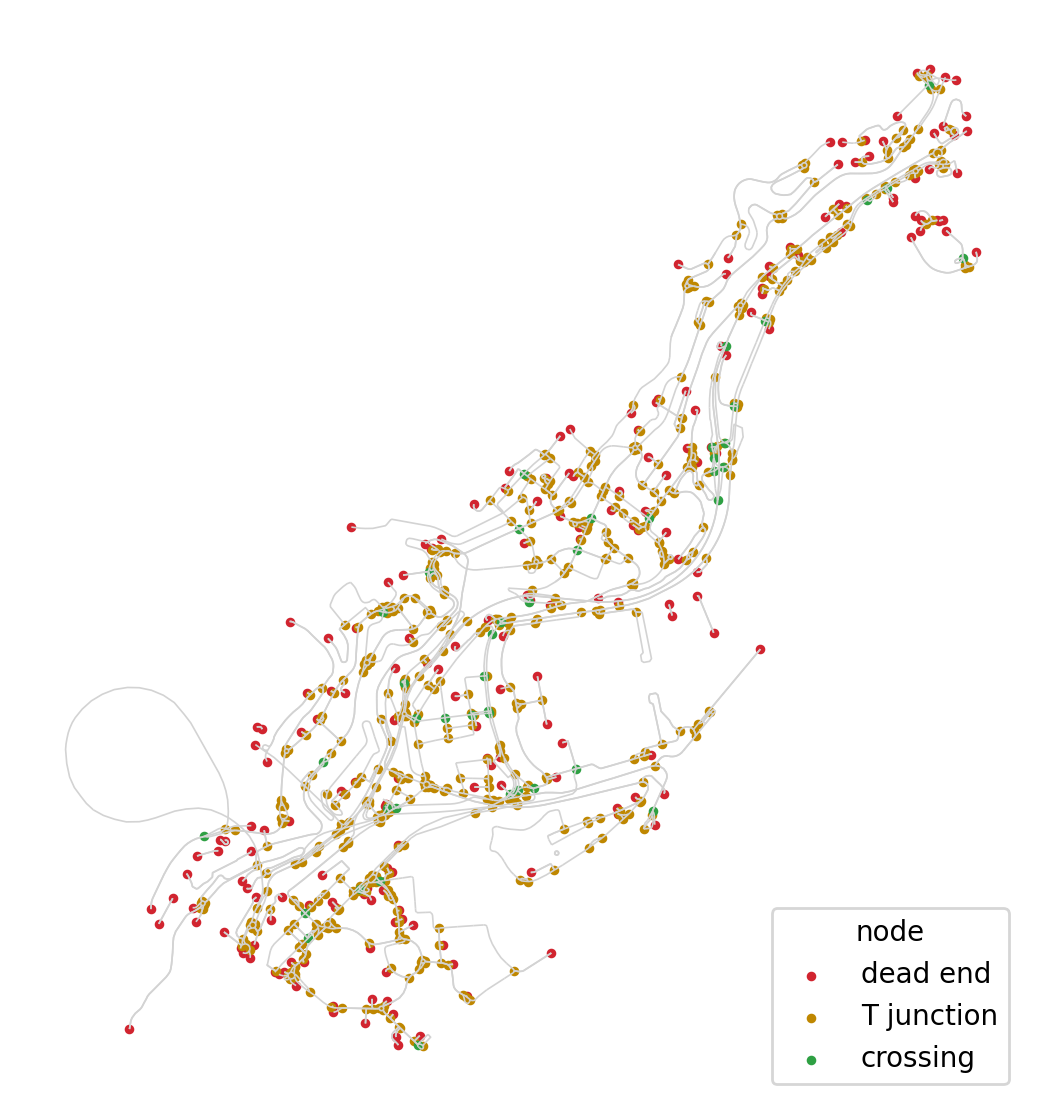

In [8]:
import matplotlib.pyplot as plt

nodes = net.driving.nodes().set_index("node_id")                  # the nodes, with their points
nodes["streets"] = spn                                            # the count of streets at each node
fig, ax = plt.subplots(figsize=(7, 7))
net.driving.edges().plot(ax=ax, color="lightgray", linewidth=0.6)      # the roads in gray
classes = [(1, "#d1242f", "dead end"), (3, "#bf8700", "T junction"), (4, "#2ea043", "crossing")]
for k, color, label in classes:
    nodes[nodes.streets == k].plot(ax=ax, color=color, markersize=6, label=label)    # the nodes of the class
ax.legend(title="node", loc="lower right")
ax.set_axis_off()
plt.show()

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The counts are the classes of the `duckosm` view: 948 nodes with two streets, 567 T junctions, 207 dead ends and 44 crossings. Monaco has few crossings: its streets meet mostly at T junctions, on the slopes. Many dead ends are at the edge of the city, where the boundary cuts the streets, and at the entries of garages.

## Street directions

### The bearing of each edge: `bearings`

`bearings(view)` gives the compass bearing of each edge, from its source node to its target node: 0 is north, 90 is
east, 180 is south and 270 is west. The result is a Series with the `edge_id` as its index. A self-loop has `NaN`.

In [9]:
brg = an.bearings(net.driving)                    # edge_id -> bearing in degrees
brg.describe().round(1)                     # the spread of the bearings

count    2840.0
mean      169.0
std       102.6
min         0.2
25%        73.3
50%       174.1
75%       246.7
max       359.3
Name: bearing, dtype: float64

### Grid or not: `orientation_entropy`

`orientation_entropy(view)` puts the bearings into `num_bins` bins (default 36 bins of 10 degrees) and gives the
entropy of the bins. The entropy is large when the streets go in all directions, and small when they go in few.

| Network | Entropy |
|---|---|
| the streets go in all directions equally | ln(36) = 3.58 |
| a perfect grid (four directions) | ln(4) = 1.39 |

`weight="length"` lets a long street count more than a short street.

In [10]:
print("orientation entropy:", round(an.orientation_entropy(net.driving), 3))                        # each street counts once
print("weighted by length:", round(an.orientation_entropy(net.driving, weight="length"), 3))         # a long street counts more

orientation entropy: 3.528
weighted by length: 3.48


The entropy of Monaco is 3.528, near the largest value of 3.58: the streets go in almost all directions. With `weight="length"` it is 3.48: the long streets have a few more common directions, along the coast from southwest to northeast.

### The polar histogram: `plot_orientation`

`plot_orientation(view)` draws the bearings as a polar histogram, as OSMnx does. The area of each bar shows its share.
It gives `(fig, ax)`, so you can put it into your own figure with `ax=` and give it a `title=`.

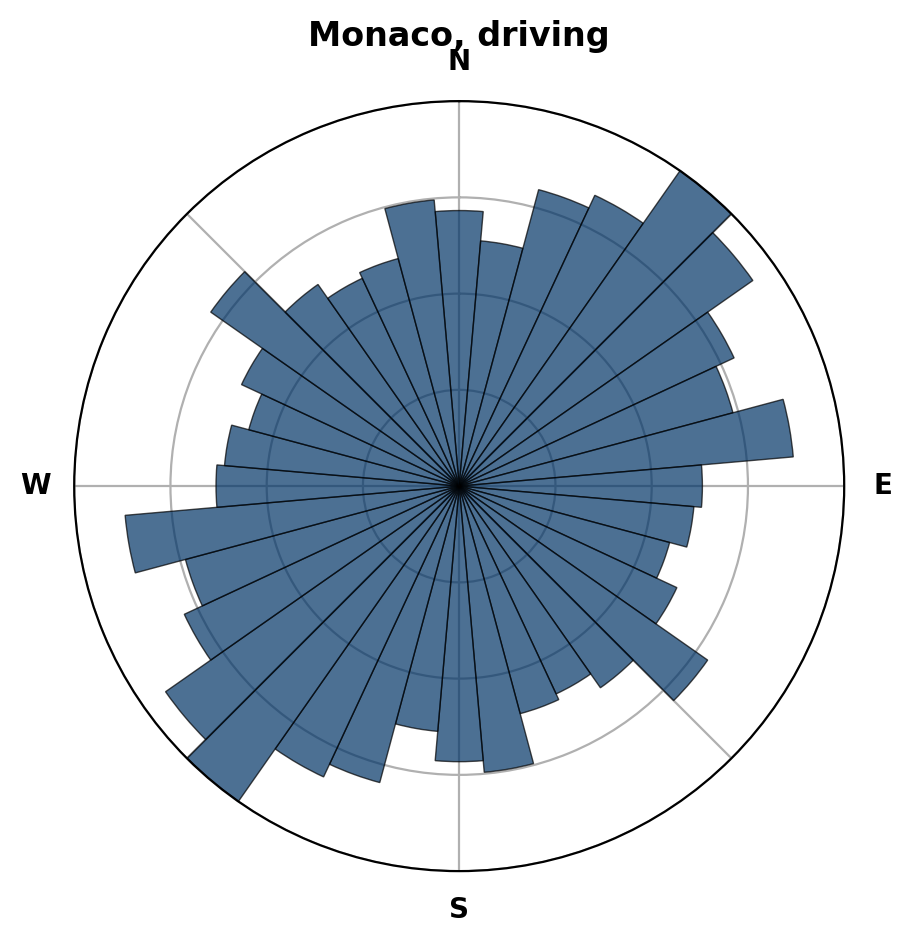

In [11]:
fig, ax = an.plot_orientation(net.driving, title="Monaco, driving")          # the polar histogram
plt.show()                                                             # the picture

The bars are of almost equal size in all directions. The longest bars point to the northeast and to the southwest, along the coast. A city with a grid shows four long bars at right angles.

## Connected parts

### The component of each node: `components`

A **strongly connected component** is a set of nodes in which you can go from each node to each other node, along the
directions of the edges. `components(view)` gives the component of each node, as a Series with the `node_id` as its
index. Component 0 is the largest, 1 is the next, and so on. `strong=False` gives the weakly connected components: the
directions of the edges do not count.

In [12]:
comp = an.components(net.driving)                                               # node_id -> part (0 = the largest)
print(f"{comp.nunique()} parts; the largest has {(comp == 0).sum():,} of {len(comp):,} nodes")    # the sizes
weak = an.components(net.driving, strong=False)                                 # the directions do not count
print(f"weakly connected: {weak.nunique()} parts; the largest has {(weak == 0).sum():,} nodes")

122 parts; the largest has 1,600 of 1,768 nodes
weakly connected: 16 parts; the largest has 1,718 nodes


> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The driving network has 122 strongly connected parts. The largest has 1,600 of the 1,768 nodes. The other 121 parts are small: most are one node, for example the end of a one-way garage ramp that only leaves the network. When the directions do not count, the network has only 16 parts, and the largest has 1,718 nodes.

### The largest part: `largest_component`

`largest_component(view, out=...)` writes a new network file with only the largest component of the mode. The mode
keeps the nodes, the edges and the turn tables of that component. The other modes of the file do not change. Use it
before an analysis that needs a connected graph, for example a matrix of all pairs. The map shows the edges outside
the largest part in orange.

In [13]:
big = an.largest_component(net.driving, out="data/monaco_largest.duckdb")    # a new network file
edges = net.driving.edges()                                  # all driving edges
inside = edges.edge_id.isin(big.driving.edges().edge_id)     # True for an edge of the largest part
print(inside.sum(), "of", len(edges), "edges are in the largest part")

2622 of 2840 edges are in the largest part


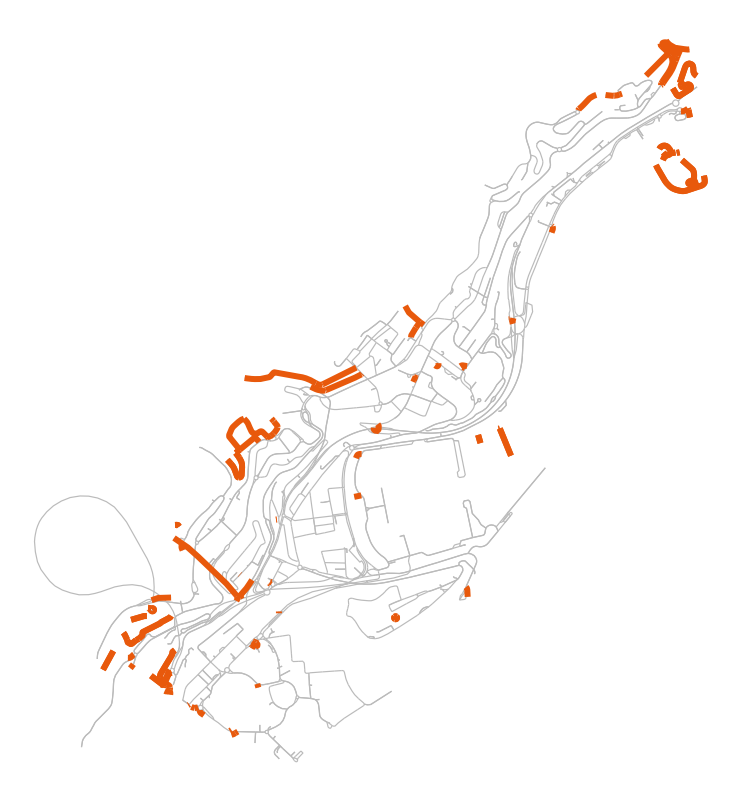

In [14]:
net.driving.plot(highlight=edges.edge_id[~inside])    # the edges outside the largest part, in orange

The largest part has 2,622 of the 2,840 edges. The 218 orange edges are outside it: garage ramps, private service roads, and short roads at the boundary of the city that you can enter but not leave (or leave but not enter).

## From points to the network

`nearest_nodes(view, x, y)` and `nearest_edges(view, x, y)` join points to the network: addresses, sensors, GPS
points or bus stops. `x` is the longitudes and `y` the latitudes, as numbers or arrays. The result has the same shape:
an array for arrays, a number for a number. `return_dist=True` also gives the distances in metres.

`nearest_edges` measures the distance to the line of the edge. The two edges of a two-way road are at the same
distance, so the edge with the lower `edge_id` comes.

Here the points are ten random points in the box of the network (black). The edge of each point is orange.

In [15]:
import numpy as np

rng = np.random.default_rng(1)                           # random points that do not change
west, south, east, north = edges.total_bounds            # the box of the network
xs = rng.uniform(west, east, 10)                         # 10 longitudes
ys = rng.uniform(south, north, 10)                       # 10 latitudes

In [16]:
ids, dist = an.nearest_edges(net.driving, xs, ys, return_dist=True)    # the nearest edge of each point
node_ids = an.nearest_nodes(net.driving, xs, ys)                        # the nearest node of each point
pd.DataFrame({"edge_id": ids, "distance_m": dist.round(1), "node_id": node_ids}).head(3)    # the first three

,edge_id,distance_m,node_id
0,1754122589688343229,374.9,25212793
1,2179780264819535765,618.3,12136114443
2,3363728794791538739,12.1,1784107000


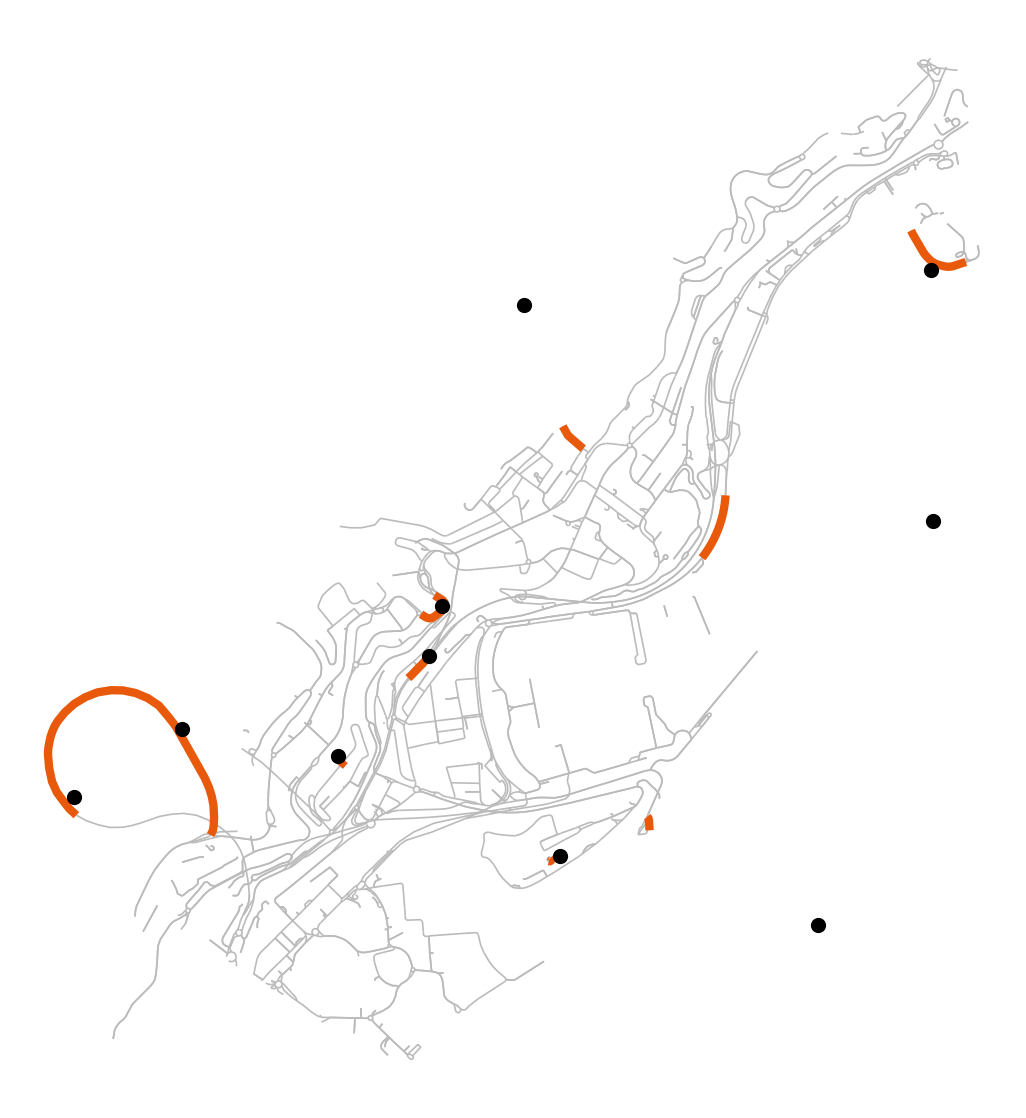

In [17]:
fig, ax = plt.subplots(figsize=(7, 7))
net.driving.plot(highlight=ids, ax=ax)                        # the edges of the points in orange
ax.scatter(xs, ys, color="black", s=20, zorder=3)             # the points
plt.show()

The table has the `edge_id` and the `node_id` of each point, and the distance to the edge in metres. The first two points are 375 m and 618 m from a road: they are in the sea, in the box of the network but outside the city. The third point is 12 m from its road. The map shows each point and its edge.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> To put your own data on the network, join the `edge_id` of `nearest_edges` to your rows. Chapter [4. Join your data by edge_id](04_join_by_edge_id.md) shows the join.

## A smaller area: `clip`

`clip(net, ...)` writes a new network file with the edges inside an area. Give one area:

| Argument | The area |
|---|---|
| `bbox=(west, south, east, north)` | a box in degrees |
| `polygon=` | a shapely polygon or a GeoJSON |
| `point=(lon, lat)` with `dist_m=` | the circle of `dist_m` metres around the point |

An edge that crosses the border stays whole, as in a build (chapter [1. Get and build an area](01_area_to_network.md)).
Here the area is 500 m around the casino square.

702 of 2840 edges


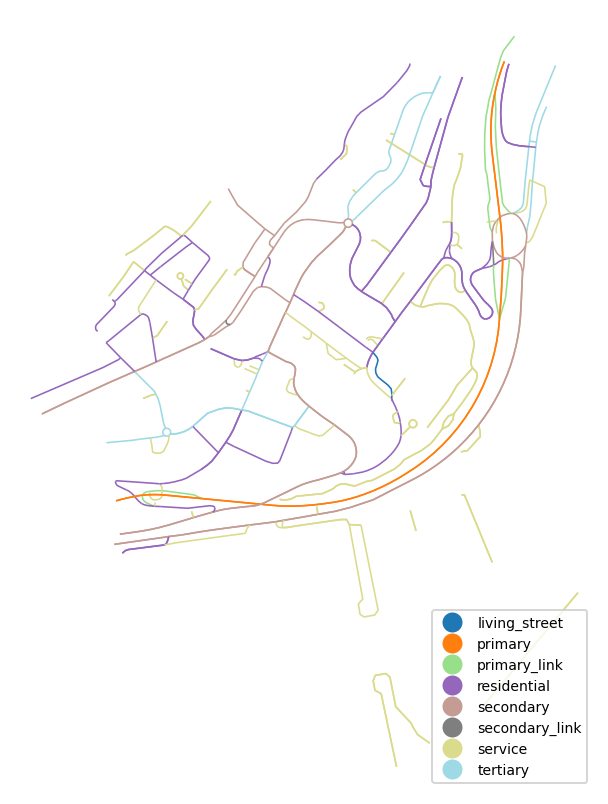

In [18]:
small = an.clip(net, point=(7.4280, 43.7393), dist_m=500, out="data/monaco_casino.duckdb")    # a new network file
print(len(small.driving.edges()), "of", len(net.driving.edges()), "edges")      # the size
small.driving.plot()                                                    # its roads by class

The circle of 500 m around the casino square holds 702 of the 2,840 edges. The new file is a full network, with its own nodes and turn tables, so every call of this chapter and of the routing chapters works on it.

## Random points on the roads: `sample_points`

`sample_points(view, n, seed=...)` gives `n` random points on the streets, as a GeoDataFrame with the `edge_id` of
each point. A street is chosen with a chance that follows its length, so a longer street gets more points. The two
edges of a two-way road count as one street. The same `seed` gives the same points. Use the points as random trip
starts or to test a sensor plan.

In [19]:
pts = an.sample_points(net.driving, 200, seed=1)          # a GeoDataFrame of points with edge_id
print(len(pts), "points on", pts.edge_id.nunique(), "edges")
pts.head(3)                                               # the first points

200 points on 168 edges


,edge_id,geometry
0,3573362122345682814,POINT (7.41198 43.72807)
1,8503051478251022153,POINT (7.41666 43.732)
2,1061984460650555701,POINT (7.42884 43.74604)


The 200 points are on 168 edges: a long edge can get more than one point.

## Heights and grades

### Add the ground height: `add_elevation`

`add_elevation(net)` adds the ground height to the nodes (`ele`) and to the edges (`z_from`, `z_to`, `z_vertices`). It
changes the file in place. `dem=` takes a DEM file (GeoTIFF) of your own. Without it, the call finds a source for the
area (`source="auto"`) and downloads its tiles into the cache. For Monaco the source is Copernicus.
[Add elevation](../guides/elevation.md) gives the sources and the options.

In [20]:
an.add_elevation(net.driving)                               # the heights of a DEM source for the area
net.driving.nodes()["ele"].describe().round(1)                      # the heights of the nodes in metres

  source=auto → copernicus (bbox 7.41, 43.73, 7.44, 43.75)


  [driving] 1768 nodes sampled (0 nodata/fill) -> ele
  1 Copernicus tiles downloaded, 12.6 MB


count    1768.0
mean       42.6
std        33.4
min        -0.5
25%        15.3
50%        33.9
75%        65.7
max       336.4
Name: ele, dtype: float64

The progress lines show the source (Copernicus, one tile of 12.6 MB) and the 1,768 nodes that got a height. The heights go from -0.5 m at the sea to 336 m, and the median is 34 m. Monaco rises fast from the coast.

### The grade of each edge: `grades`

`grades(view)` gives `(z_to - z_from) / length_m` for each edge, as a Series with the `edge_id` as its index. 0.05 is
5 % up, and -0.05 is 5 % down. It needs `add_elevation` first.

In [21]:
g = an.grades(net.driving)                                # edge_id -> grade
print(f"the steepest of all edges: {g.abs().max():.0%}")

the steepest of all edges: 880%


In [22]:
e = net.driving.edges().set_index("edge_id")              # the edge columns
long = e.length_m >= 50                                   # 50 m or more
ground = e.tunnel.isna() & e.bridge.isna()                # not a tunnel, not a bridge
ok = g[long & ground]                                     # the grades that you can use
ok.abs().describe(percentiles=[0.5, 0.9]).round(3)        # the spread of the grades

count    471.000
mean       0.071
std        0.065
min        0.000
50%        0.051
90%        0.158
max        0.351
Name: grade, dtype: float64

Over all edges the steepest grade is 880 %: a wrong value on a tunnel or a short edge. The second cell keeps only
the edges of 50 m or more that are on the ground. For these 471 edges of 50 m or more that are not tunnels or bridges, the steepest is 35 %, the median is 5.1 % and 90 % of the edges are below 15.8 %. Monaco is a steep city.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> A DEM gives the height of the ground. A tunnel or a bridge is not on the ground, so its grade from the DEM is wrong. A short edge on a slope can also get a large grade from the cells of the DEM. Remove these edges before you use the grades.

## OSMnx on the network: `to_osmnx`

`to_osmnx(view)` gives the mode as the `networkx.MultiDiGraph` of OSMnx. Each OSMnx function works on it: the graph
passes `ox.convert.validate_graph`. The node keys are the `node_id`. Each edge keeps its `edge_id` and has the OSMnx
names: `osmid`, `length`, `geometry`, `highway`, `name`, `oneway`, `lanes`, `speed_kph` and `travel_time`.

Here OSMnx finds a route on the largest part (`big`, above) with its own `shortest_path`.

In [23]:
import osmnx as ox

G = an.to_osmnx(big.driving)          # the largest part as a networkx MultiDiGraph
print(G)                              # its size

MultiDiGraph named 'monaco_largest' with 1600 nodes and 2622 edges


In [24]:
orig, dest = an.nearest_nodes(big.driving, [7.4155, 7.4370], [43.7310, 43.7480])    # two nodes (duckOSM finds them)
route = ox.routing.shortest_path(G, orig, dest, weight="travel_time")              # OSMnx's route: a list of node_id
route_edges = ox.routing.route_to_gdf(G, route)                                    # its edges, with the OSMnx columns
len(route_edges), round(route_edges["length"].sum()), round(route_edges["travel_time"].sum())    # edges, metres, seconds

(67, 2889, 202)

The graph of the largest part has 1,600 nodes and 2,622 edges, the same as `big`. OSMnx found a route on it with
its own `shortest_path`: 67 edges, 2,889 m and 202 s.

### Check: the `osmnx` view gives the numbers of OSMnx

Section "Statistics: `stats`" says that the `osmnx` view of `stats` gives the numbers of OSMnx. This check proves it:
it computes the same numbers in two ways, on the same driving network of Monaco, and compares them.

| Way | What it does |
|---|---|
| duckOSM | `an.stats(net.driving)["osmnx"]`: the `osmnx` view of duckOSM's own statistics |
| OSMnx | `to_osmnx` gives the network to OSMnx, OSMnx simplifies it (it removes the nodes where only two roads meet), and `ox.basic_stats` counts it |

One detail: `to_osmnx` marks the graph as simplified, because each edge already has its full line. OSMnx does not
simplify a graph with that mark. So the cell sets `H.graph["simplified"] = False` first, and then OSMnx simplifies it
as it does with its own graphs.

In [25]:
H = an.to_osmnx(net.driving)                                     # the whole driving network, as an OSMnx graph
H.graph["simplified"] = False                              # allow OSMnx to simplify it
theirs = ox.basic_stats(ox.simplify_graph(H))              # the numbers of OSMnx
ours = an.stats(net.driving)["osmnx"]                            # the numbers of duckOSM's osmnx view
keys = ["n", "m", "intersection_count", "street_segment_count"]
pd.DataFrame({"duckOSM": [ours[k] for k in keys], "OSMnx": [theirs[k] for k in keys]}, index=keys)    # side by side

,duckOSM,OSMnx
n,843,843
m,1484,1484
intersection_count,636,636
street_segment_count,1070,1070


The two columns are the same: 843 nodes (`n`), 1,484 edges (`m`), 636 intersections and 1,070 street segments.
So you can use `an.stats` and compare its `osmnx` view with any number that OSMnx gives for another city. The tests
of duckOSM run this check for each key.

## City blocks with momepy

A city block is the land between streets, with its buildings. Planners use blocks to compare parts of a city: small
blocks make a city easy to walk, and large blocks make long detours. [momepy](https://docs.momepy.org) is a Python
library that measures the shape of a city. It makes the blocks from three layers. duckOSM gives all three from the same
OSM file:

| Layer | From duckOSM |
|---|---|
| The streets | the edges of the network (`net.driving.edges()`, `net.walking.edges()`) |
| The buildings | `duckosm.gis.features(net, tags={"building": True})` (chapter 10) |
| The land | the boundary of the area (`net.boundary`) less the water |

momepy makes the blocks in three steps:

1. **Enclosures:** it cuts the land along the streets. Each enclosure is an area with streets around it.
2. **Cells:** it divides each enclosure into one cell for each building (a tessellation). A cell is the land that is
   nearer to its building than to other buildings.
3. **Blocks:** it joins the cells of the buildings that are between the same streets.

### The streets

momepy needs one line for each street, in metres. The network has one edge for each direction of a two-way street,
so the cell keeps the edges with `is_reverse` false. It takes the walking edges too: in Monaco many streets join only
by steps and footways. It removes the tunnels, because a tunnel does not cut the land above it.

In [26]:
import momepy

lines = pd.concat([net.driving.edges(), net.walking.edges()])      # the edges of two modes
lines = lines.drop_duplicates("edge_id")                           # a road of both modes counts once
lines = lines[~lines.is_reverse & lines.tunnel.isna()]             # one line for each street, no tunnels
crs = lines.estimate_utm_crs()                                     # the UTM zone of Monaco: coordinates in metres
streets = lines.to_crs(crs)[["edge_id", "highway", "geometry"]]
len(streets)

6115

### The buildings and the land

The buildings are the OSM areas with a `building` tag. The land is the boundary less the water: the lakes
(`natural=water`) and the two ports of Monaco (`leisure=marina`).

In [27]:
buildings = duckosm.gis.features(net, tags={"building": True}).to_crs(crs)       # the OSM buildings
buildings = buildings[buildings.geom_type.isin(["Polygon", "MultiPolygon"])]       # only the areas
buildings = buildings.explode(index_parts=False).reset_index(drop=True)[["geometry"]]   # one polygon for each row
water = duckosm.gis.features(net, tags={"natural": ["water"], "leisure": ["marina"]}).to_crs(crs)   # lakes and ports
land = net.boundary.to_crs(crs).difference(water.union_all())                      # the city without its water
len(buildings), round(land.area.sum() / 1e6, 2)                                    # buildings, land in km²

(1258, np.float64(2.08))

### The three steps

`momepy.enclosures` cuts the land along the streets. A port is a hole in the land, and momepy also gives the hole as
an enclosure, so the second line removes the enclosures that are not on the land. `momepy.generate_blocks` gives two
results: the blocks, and the block of each building.

In [28]:
enc = momepy.enclosures(streets, limit=land)                       # step 1: the areas between the streets
enc = enc[enc.representative_point().within(land.union_all())]     # remove the ports (holes in the land)
cells = momepy.enclosed_tessellation(buildings, enc)               # step 2: one cell for each building
blocks, block_of = momepy.generate_blocks(cells, streets, buildings)    # step 3: the cells joined into blocks
len(enc), len(cells), len(blocks)

(1710, 2711, 292)

The land has 2.08 km² and 1,710 enclosures. The 1,258 buildings give 2,711 cells. There are more cells than
buildings, because an enclosure with no building is also a cell. momepy joins the cells into 292 blocks.

### The size of the blocks

The cell gives each block its area in hectares (1 ha = 10,000 m², about a football field and a half) and puts it in a
size class.

In [29]:
blocks["ha"] = blocks.area / 10_000                                # the area in hectares
classes = ["< 0.1 ha", "0.1-0.5 ha", "0.5-1 ha", "1-5 ha", "> 5 ha"]
blocks["size"] = pd.cut(blocks.ha, [0, 0.1, 0.5, 1, 5, 1000], labels=classes)
blocks["size"].value_counts().sort_index()                         # the blocks in each class

size
< 0.1 ha       57
0.1-0.5 ha    149
0.5-1 ha       43
1-5 ha         39
> 5 ha          4
Name: count, dtype: int64

Most blocks are small: 149 blocks have 0.1 to 0.5 ha, and 57 have less than 0.1 ha. Only 4 blocks have more
than 5 ha. They are on the coast and on the slopes, where few streets cut the land, for example at the Larvotto beach
in the northeast.

The blocks change with the streets that you give to momepy. With the driving streets only, many steps and footways
do not cut the land, and the blocks become larger.

### The map of the blocks

On the map, each block is a half-transparent polygon with a strong border, on top of the buildings and the roads. So
you see where one block stops and the next one starts, and what is inside it. Two blocks that touch never have the
same color: `mapclassify.greedy` gives each block one of six colors in this way. The size of the blocks is in the
table above, not on the map. The plain gray areas in the middle are the two ports.

The map has four layers, from the bottom to the top:

| Layer | Style |
|---|---|
| The buildings | gray |
| The roads | white: wide for a main road (`primary`, `secondary`, ...), narrow for a street |
| The footways and the steps | brown dashed lines |
| The blocks | half-transparent, with a border in the same color; two blocks that touch never have the same color |

The first cell gives each block its color, and each road its kind and its style. The second cell draws the map.

In [ ]:
import mapclassify

blocks["color"] = mapclassify.greedy(blocks, min_colors=6)                       # 0 to 5: blocks that touch differ
main = ["motorway", "trunk", "primary", "secondary", "tertiary"]
paths = ["footway", "steps", "pedestrian", "path", "cycleway", "corridor"]
kind = pd.Series("street", index=streets.index)                                 # each road is a street, but:
kind[streets.highway.str.replace("_link", "").isin(main)] = "main road"         # primary_link counts as primary
kind[streets.highway.isin(paths)] = "footway, steps"
roads = {"footway, steps": dict(color="#8b4513", linewidth=0.5, linestyle="--"),
         "street": dict(color="white", linewidth=1.0),
         "main road": dict(color="white", linewidth=2.2)}
kind.value_counts()                                                             # the roads of each kind

footway, steps    4184
street            1210
main road          721
Name: count, dtype: int64

The map has 4,184 footways and steps, 1,210 streets and 721 main roads. Most lines are footways and steps:
Monaco has many of them between its streets, on the slopes.

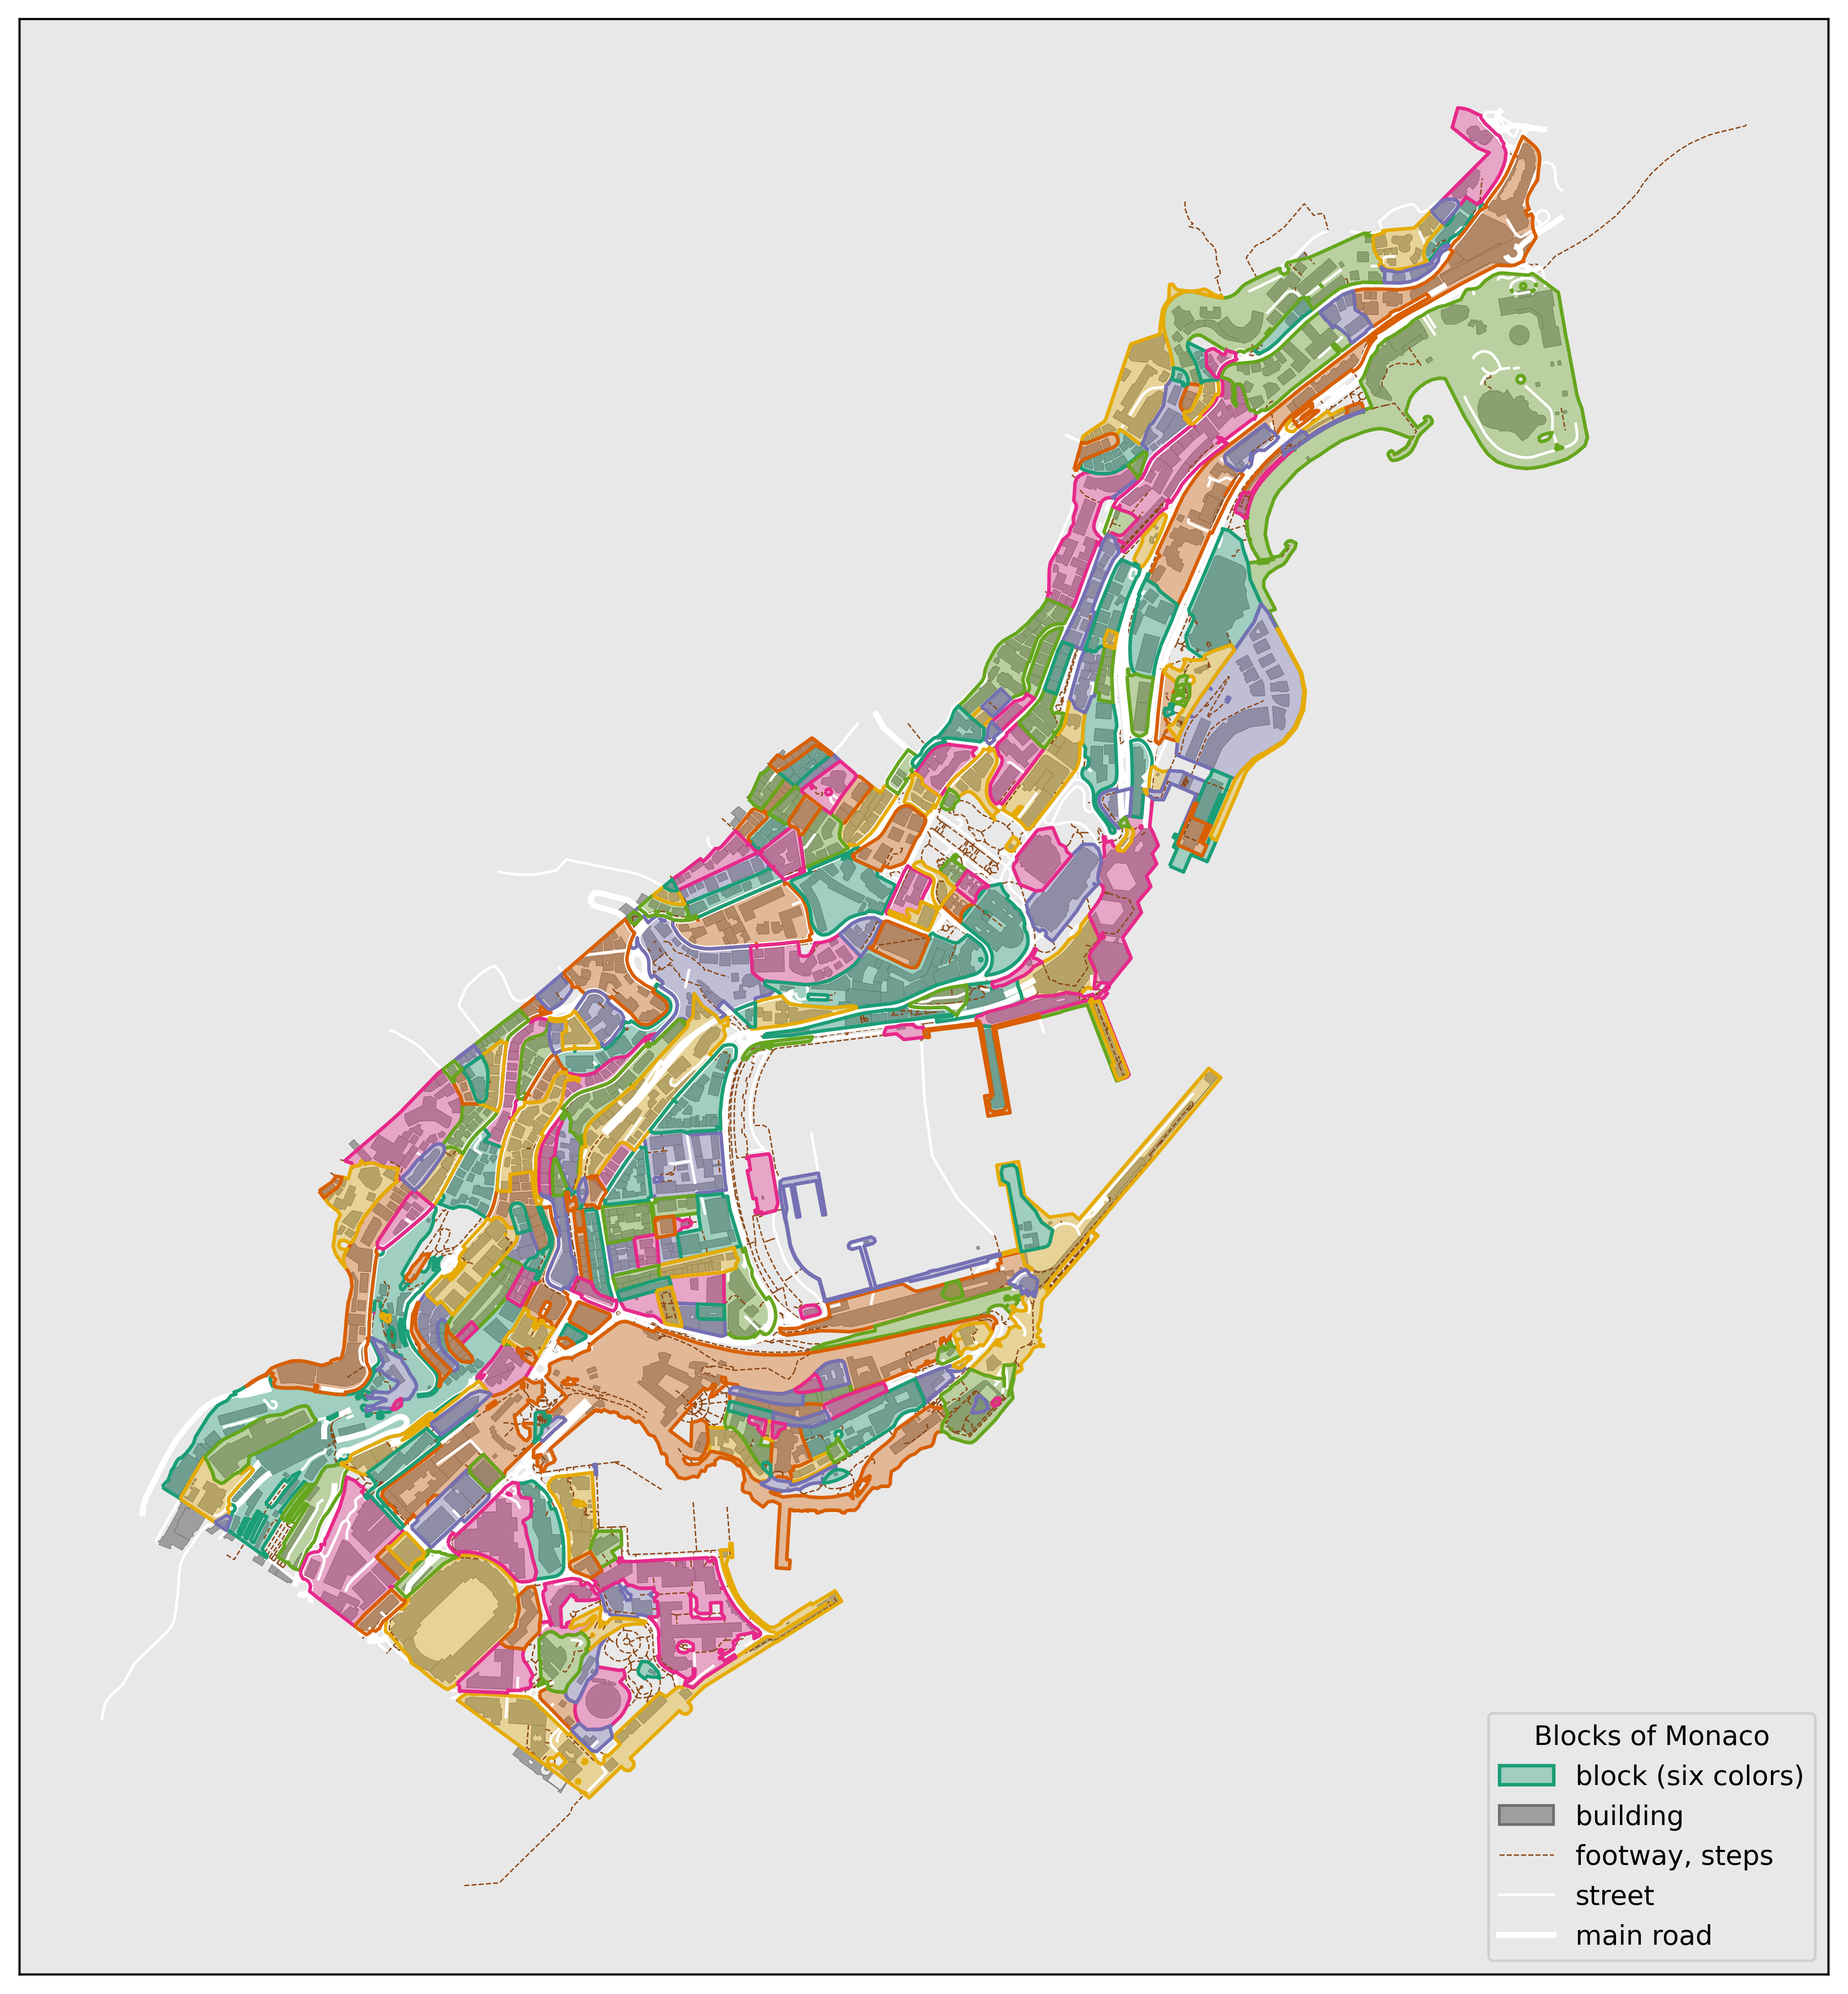

In [ ]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

six = ListedColormap(["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02"])    # the six block colors
fig, ax = plt.subplots(figsize=(12, 13), dpi=200)          # a large picture with many pixels: zoom in to see each block
ax.set_facecolor("#e8e8e8")                                # the background in light gray
buildings.plot(ax=ax, color="#9e9e9e", edgecolor="#6e6e6e", linewidth=0.2)      # the buildings
for k, style in roads.items():
    streets[kind == k].plot(ax=ax, **style)                                     # the roads
blocks.plot(ax=ax, column="color", cmap=six, alpha=0.35)                        # each block: a half-transparent polygon
blocks.boundary.plot(ax=ax, color=[six(c) for c in blocks.color], linewidth=1.3)    # and its border, in its color
legend = [Patch(facecolor=(0.11, 0.62, 0.47, 0.35), edgecolor="#1b9e77", linewidth=1.3, label="block (six colors)"),
          Patch(facecolor="#9e9e9e", edgecolor="#6e6e6e", label="building")]
legend += [Line2D([], [], label=k, **style) for k, style in roads.items()]
ax.legend(handles=legend, title="Blocks of Monaco", loc="lower right", facecolor="#e8e8e8")
ax.set_xticks([])
ax.set_yticks([])
plt.show()

## Try it yourself

**1.** Give the statistics of the walking network of Monaco, and compare `streets_per_node_avg` with driving.

<details><summary>Show the answer</summary>

```python
an.stats(net.walking).loc[["n", "m", "streets_per_node_avg"]]
```
</details>

**2.** Count the dead ends of the network of 500 m around the casino square (`small`, above).

<details><summary>Show the answer</summary>

```python
(an.streets_per_node(small.driving) == 1).sum()
```
</details>

**3.** Clip the network to a box around the port, and give its orientation entropy.

<details><summary>Show the answer</summary>

```python
port = an.clip(net, bbox=(7.418, 43.730, 7.430, 43.738), out="data/port.duckdb")
an.orientation_entropy(port.driving)
```
</details>

**4.** Draw the edges whose grade is more than 10 % (on the ground, 50 m or more).

<details><summary>Show the answer</summary>

```python
steep = ok[ok.abs() > 0.10].index
net.plot(highlight=list(steep))
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| street network analysis | the description of the form of a road network with numbers |
| view | a way to count the nodes and edges: `osmnx` (2-road nodes removed) or `duckosm` (every row) |
| intersection | a node where 2 or more streets meet (OSMnx's rule) |
| dead end | a node with one street |
| circuity | the length of a street divided by the straight distance between its ends |
| bearing | the compass direction of an edge, from 0 (north) to 360 degrees |
| orientation entropy | a number for the spread of the street directions: 1.39 for a grid, 3.58 for all directions |
| strongly connected component | a set of nodes where you can go from each node to each other node along the edge directions |
| DEM | a digital elevation model: a raster of ground heights |
| grade | the change of height of an edge divided by its length |

## Summary

| Call | Does |
|---|---|
| `an.stats(view, area_m2=...)` | the numbers of OSMnx `basic_stats`, in two views |
| `an.streets_per_node(view)` | the streets at each node |
| `an.bearings(view)` | the compass bearing of each edge |
| `an.orientation_entropy(view, weight=...)` | the entropy of the street directions |
| `an.plot_orientation(view, title=...)` | the polar histogram of the bearings |
| `an.components(view, strong=...)` | the connected component of each node |
| `an.largest_component(view, out=...)` | a new file with the largest component |
| `an.nearest_nodes(view, x, y)`, `an.nearest_edges(view, x, y)` | the nearest node and edge of each point |
| `an.clip(net, point=..., dist_m=...)` | a new file with the edges inside an area |
| `an.sample_points(view, n, seed=...)` | random points on the streets |
| `an.add_elevation(net, dem=...)`, `an.grades(view)` | the heights, and the grade of each edge |
| `an.to_osmnx(view)` | the network as an OSMnx graph |

The reference: [duckosm.analysis](../reference/sdk/analysis.md). **Next:** [10. OSM data for GIS](10_gis.md), OSM features, OSM XML and administrative areas.